In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

sns.set_theme(style="whitegrid")

valid = pd.read_parquet("../data/processed/valid.parquet")
X_valid = valid.drop(columns=["target"])
y_valid = valid["target"]

logistic = joblib.load("../models/logistic_baseline.joblib")
lgbm = joblib.load("../models/lightgbm_v2.joblib")

p_logistic = logistic.predict_proba(X_valid)[:, 1]
p_lgbm = lgbm.predict_proba(X_valid)[:, 1]

sub_grade_order = {
    f"{g}{n}": (i - 1) * 5 + n
    for i, g in enumerate("ABCDEFG", start=1)
    for n in range(1, 6)
}
score_sub_grade = valid["sub_grade"].map(sub_grade_order)

print("LightGBM validation AUC:", round(roc_auc_score(y_valid, p_lgbm), 4))

LightGBM validation AUC: 0.6951


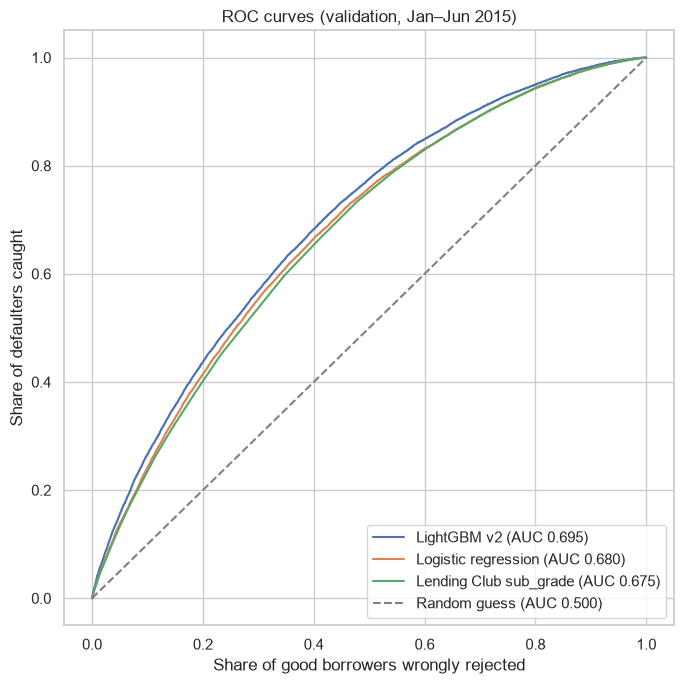

In [2]:
models = {
    "LightGBM v2": p_lgbm,
    "Logistic regression": p_logistic,
    "Lending Club sub_grade": score_sub_grade,
}

fig, ax = plt.subplots(figsize=(7, 7))

for name, scores in models.items():
    fpr, tpr, _ = roc_curve(y_valid, scores)
    auc = roc_auc_score(y_valid, scores)
    ax.plot(fpr, tpr, label=f"{name} (AUC {auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC 0.500)")
ax.set_xlabel("Share of good borrowers wrongly rejected")
ax.set_ylabel("Share of defaulters caught")
ax.set_title("ROC curves (validation, Jan–Jun 2015)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("../results/figures/roc_curves_validation.png", dpi=120)
plt.show()

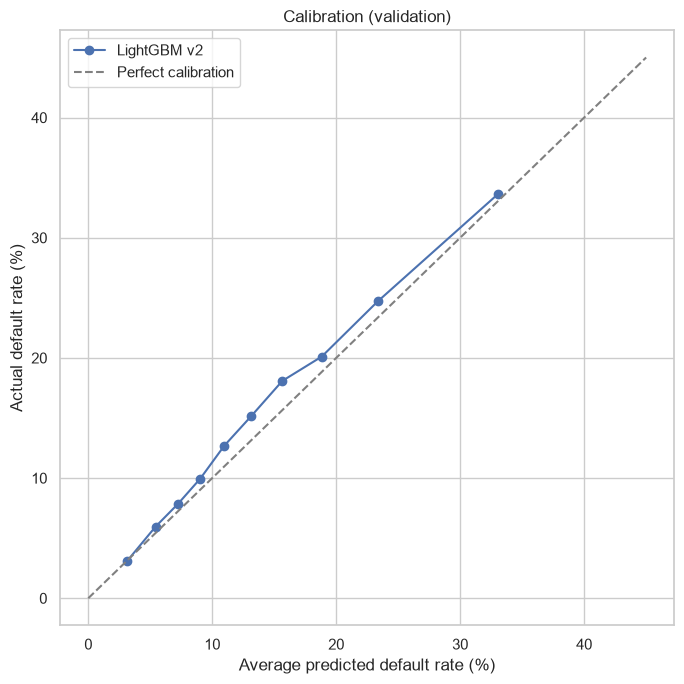

,loans,avg_predicted,actual_rate
group,,,
0,12079,0.0315,0.0311
1,12079,0.0542,0.0595
2,12079,0.0722,0.0784
3,12079,0.0904,0.0996
4,12079,0.1097,0.1269
5,12079,0.1313,0.1513
6,12079,0.1566,0.1809
7,12079,0.1883,0.2011
8,12079,0.2334,0.2470


In [3]:
def calibration_table(y_true, probabilities, groups=10):
    data = pd.DataFrame({"actual": y_true.values, "predicted": probabilities})
    data["group"] = pd.qcut(data["predicted"], q=groups, labels=False, duplicates="drop")
    return data.groupby("group").agg(
        loans=("actual", "size"),
        avg_predicted=("predicted", "mean"),
        actual_rate=("actual", "mean"),
    )


cal_before = calibration_table(y_valid, p_lgbm)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(cal_before["avg_predicted"] * 100, cal_before["actual_rate"] * 100,
        marker="o", label="LightGBM v2")
ax.plot([0, 45], [0, 45], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Average predicted default rate (%)")
ax.set_ylabel("Actual default rate (%)")
ax.set_title("Calibration (validation)")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/calibration_before.png", dpi=120)
plt.show()

cal_before.round(4)

In [4]:
from sklearn.linear_model import LogisticRegression
from src.models import CalibratedModel, logit

calibrator = LogisticRegression()
calibrator.fit(logit(p_lgbm).reshape(-1, 1), y_valid)

lgbm_calibrated = CalibratedModel(lgbm, calibrator)
p_calibrated = lgbm_calibrated.predict_proba(X_valid)[:, 1]

summary = pd.DataFrame({
    "auc": [roc_auc_score(y_valid, p_lgbm), roc_auc_score(y_valid, p_calibrated)],
    "brier": [brier_score_loss(y_valid, p_lgbm), brier_score_loss(y_valid, p_calibrated)],
    "avg_predicted": [p_lgbm.mean(), p_calibrated.mean()],
}, index=["Before correction", "After correction"])

print("Actual default rate:", round(y_valid.mean(), 4))
summary.round(4)

Actual default rate: 0.1512


,auc,brier,avg_predicted
Before correction,0.6951,0.1205,0.1398
After correction,0.6951,0.1203,0.1513


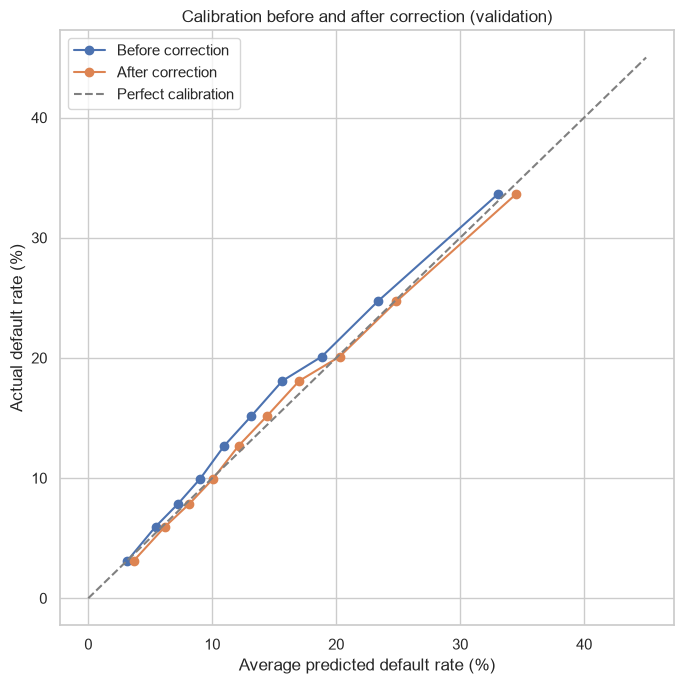

Saved.


In [5]:
cal_after = calibration_table(y_valid, p_calibrated)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(cal_before["avg_predicted"] * 100, cal_before["actual_rate"] * 100,
        marker="o", label="Before correction")
ax.plot(cal_after["avg_predicted"] * 100, cal_after["actual_rate"] * 100,
        marker="o", label="After correction")
ax.plot([0, 45], [0, 45], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Average predicted default rate (%)")
ax.set_ylabel("Actual default rate (%)")
ax.set_title("Calibration before and after correction (validation)")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/calibration_after.png", dpi=120)
plt.show()

joblib.dump(lgbm_calibrated, "../models/lightgbm_v2_calibrated.joblib")
print("Saved.")

In [6]:
eval_df = valid[["annual_inc", "home_ownership", "verification_status",
                 "purpose", "addr_state"]].copy()
eval_df["actual"] = y_valid.values
eval_df["predicted"] = p_calibrated

eval_df["income_band"] = pd.qcut(
    eval_df["annual_inc"], q=4,
    labels=["Lowest 25%", "Lower-middle 25%", "Upper-middle 25%", "Highest 25%"],
)


def group_report(column, min_loans=1000):
    rows = []
    for value, group in eval_df.groupby(column, observed=True):
        if len(group) < min_loans:
            continue
        rows.append({
            column: value,
            "loans": len(group),
            "actual_pct": group["actual"].mean() * 100,
            "predicted_pct": group["predicted"].mean() * 100,
            "auc": roc_auc_score(group["actual"], group["predicted"]),
        })
    report = pd.DataFrame(rows).set_index(column)
    report["difference_pct"] = report["predicted_pct"] - report["actual_pct"]
    return report.round(3)


for col in ["income_band", "home_ownership", "verification_status", "purpose"]:
    print(f"\n{col}")
    display(group_report(col))


income_band


,loans,actual_pct,predicted_pct,auc,difference_pct
income_band,,,,,
Lowest 25%,30741,19.248,19.993,0.652,0.745
Lower-middle 25%,30326,15.980,15.984,0.683,0.004
Upper-middle 25%,29525,13.873,13.506,0.702,-0.367
Highest 25%,30198,11.292,10.896,0.715,-0.396



home_ownership


,loans,actual_pct,predicted_pct,auc,difference_pct
home_ownership,,,,,
MORTGAGE,54263,12.185,12.601,0.700,0.416
OWN,13180,15.827,15.867,0.683,0.040
RENT,53347,17.941,17.513,0.677,-0.428



verification_status


,loans,actual_pct,predicted_pct,auc,difference_pct
verification_status,,,,,
Not Verified,40674,12.305,12.379,0.691,0.074
Source Verified,49542,15.450,15.406,0.689,-0.044
Verified,30574,18.349,18.330,0.688,-0.019



purpose


,loans,actual_pct,predicted_pct,auc,difference_pct
purpose,,,,,
car,1151,12.945,13.301,0.681,0.356
credit_card,28495,12.462,12.580,0.704,0.118
debt_consolidation,71988,15.936,15.811,0.689,-0.125
home_improvement,6631,13.271,13.608,0.706,0.337
major_purchase,2046,15.005,14.323,0.707,-0.682
medical,1150,17.652,18.580,0.669,0.928
other,6031,17.145,17.685,0.685,0.540
small_business,1056,23.106,24.531,0.650,1.425


In [7]:
states = group_report("addr_state")
states["abs_difference"] = states["difference_pct"].abs()

print("States checked:", len(states))
print("Average absolute difference:", round(states["abs_difference"].mean(), 2), "percentage points")
states.sort_values("abs_difference", ascending=False).head(8).drop(columns="abs_difference")

States checked: 31
Average absolute difference: 0.86 percentage points


,loans,actual_pct,predicted_pct,auc,difference_pct
addr_state,,,,,
TN,1858,15.339,18.224,0.718,2.884
OR,1604,10.723,13.013,0.724,2.290
LA,1436,17.897,15.629,0.698,-2.268
WA,2774,11.572,13.383,0.691,1.811
MA,2672,12.463,14.107,0.700,1.644
VA,3345,14.499,15.984,0.684,1.485
CT,1737,14.623,13.193,0.682,-1.430
WI,1693,12.050,13.383,0.704,1.333


In [8]:
test = pd.read_parquet("../data/processed/test.parquet")
X_test = test.drop(columns=["target"])
y_test = test["target"]

p_test_lgbm = lgbm_calibrated.predict_proba(X_test)[:, 1]
p_test_logistic = logistic.predict_proba(X_test)[:, 1]
score_test_sub_grade = test["sub_grade"].map(sub_grade_order)


def ks_statistic(y_true, scores):
    fpr, tpr, _ = roc_curve(y_true, scores)
    return (tpr - fpr).max()


test_results = pd.DataFrame({
    "auc": [
        roc_auc_score(y_test, p_test_lgbm),
        roc_auc_score(y_test, p_test_logistic),
        roc_auc_score(y_test, score_test_sub_grade),
    ],
    "ks": [
        ks_statistic(y_test, p_test_lgbm),
        ks_statistic(y_test, p_test_logistic),
        ks_statistic(y_test, score_test_sub_grade),
    ],
}, index=["LightGBM v2 (calibrated)", "Logistic regression", "Lending Club sub_grade"])

test_results["gini"] = 2 * test_results["auc"] - 1

print("Test loans:", len(test))
print("Actual default rate:", round(y_test.mean(), 4))
print("LightGBM average predicted:", round(p_test_lgbm.mean(), 4))
print("LightGBM Brier score:", round(brier_score_loss(y_test, p_test_lgbm), 4))
test_results.round(4)

Test loans: 162236
Actual default rate: 0.1471
LightGBM average predicted: 0.1462
LightGBM Brier score: 0.117


,auc,ks,gini
LightGBM v2 (calibrated),0.7026,0.2941,0.4051
Logistic regression,0.6871,0.2706,0.3741
Lending Club sub_grade,0.6814,0.2665,0.3629


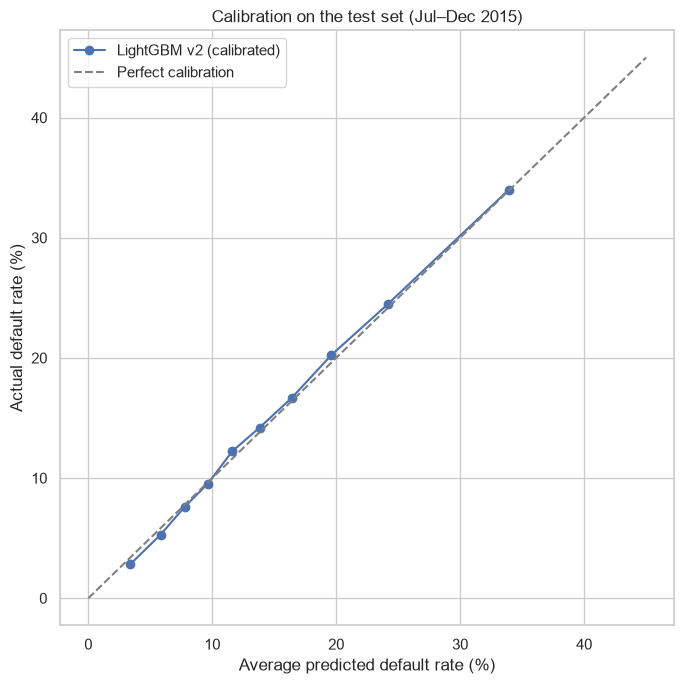

,loans,avg_predicted,actual_rate
group,,,
0,16224,0.0337,0.0282
1,16224,0.0584,0.0529
2,16223,0.0777,0.0760
3,16224,0.0964,0.0954
4,16223,0.1162,0.1224
5,16224,0.1383,0.1421
6,16223,0.1642,0.1668
7,16224,0.1962,0.2025
8,16223,0.2416,0.2448


In [9]:
cal_test = calibration_table(y_test, p_test_lgbm)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(cal_test["avg_predicted"] * 100, cal_test["actual_rate"] * 100,
        marker="o", label="LightGBM v2 (calibrated)")
ax.plot([0, 45], [0, 45], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Average predicted default rate (%)")
ax.set_ylabel("Actual default rate (%)")
ax.set_title("Calibration on the test set (Jul–Dec 2015)")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/calibration_test.png", dpi=120)
plt.show()

cal_test.round(4)

In [10]:
rng = np.random.default_rng(42)
y_array = y_test.values
lgbm_array = p_test_lgbm
grade_array = score_test_sub_grade.values

differences = []
for _ in range(200):
    sample = rng.integers(0, len(y_array), size=len(y_array))
    auc_model = roc_auc_score(y_array[sample], lgbm_array[sample])
    auc_grade = roc_auc_score(y_array[sample], grade_array[sample])
    differences.append(auc_model - auc_grade)

differences = np.array(differences)
low, high = np.percentile(differences, [2.5, 97.5])

print(f"Average AUC lead over sub_grade: {differences.mean():.4f}")
print(f"95% range: {low:.4f} to {high:.4f}")
print(f"LightGBM ahead in {(differences > 0).mean() * 100:.0f}% of samples")

Average AUC lead over sub_grade: 0.0211
95% range: 0.0182 to 0.0240
LightGBM ahead in 100% of samples


In [11]:
import json

valid_predictions = pd.DataFrame({
    "id": valid["id"].values,
    "target": y_valid.values,
    "p_lgbm": p_calibrated,
    "p_logistic": p_logistic,
})
test_predictions = pd.DataFrame({
    "id": test["id"].values,
    "target": y_test.values,
    "p_lgbm": p_test_lgbm,
    "p_logistic": p_test_logistic,
})

valid_predictions.to_parquet("../data/processed/valid_predictions.parquet", index=False)
test_predictions.to_parquet("../data/processed/test_predictions.parquet", index=False)

metrics = {
    "test_period": "2015-07 to 2015-12",
    "test_loans": int(len(test)),
    "actual_default_rate": round(float(y_test.mean()), 4),
    "lightgbm": {
        "auc": round(float(test_results.loc["LightGBM v2 (calibrated)", "auc"]), 4),
        "gini": round(float(test_results.loc["LightGBM v2 (calibrated)", "gini"]), 4),
        "ks": round(float(test_results.loc["LightGBM v2 (calibrated)", "ks"]), 4),
        "brier": round(float(brier_score_loss(y_test, p_test_lgbm)), 4),
        "avg_predicted": round(float(p_test_lgbm.mean()), 4),
    },
    "logistic_regression_auc": round(float(test_results.loc["Logistic regression", "auc"]), 4),
    "lending_club_sub_grade_auc": round(float(test_results.loc["Lending Club sub_grade", "auc"]), 4),
    "lead_over_sub_grade": {
        "mean": round(float(differences.mean()), 4),
        "ci_95_low": round(float(low), 4),
        "ci_95_high": round(float(high), 4),
    },
}

with open("../results/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))

{
  "test_period": "2015-07 to 2015-12",
  "test_loans": 162236,
  "actual_default_rate": 0.1471,
  "lightgbm": {
    "auc": 0.7026,
    "gini": 0.4051,
    "ks": 0.2941,
    "brier": 0.117,
    "avg_predicted": 0.1462
  },
  "logistic_regression_auc": 0.6871,
  "lending_club_sub_grade_auc": 0.6814,
  "lead_over_sub_grade": {
    "mean": 0.0211,
    "ci_95_low": 0.0182,
    "ci_95_high": 0.024
  }
}
